In [1]:
! pip install pandas
! pip install matplotlib
! pip install seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 10.0 MB/s eta 0:00:0000:0100:01
  Using cached numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.8 MB)
  Using cached tzdata-2025.2-py2.py3-none-any.whl (347 kB)
  Using cached pytz-2025.2-py2.py3-none-any.whl (509 kB)

[notice] A new release of pip is available: 23.0.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 10.3 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 9.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 7.0 MB/s eta 0:00:0000:01m00:01
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached pyparsing-3.2.5-py3-none-any.whl (113 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 4.1 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 1.8 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is avail

In [4]:
import json
import pandas as pd

with open("results_comparaison_R52_1_50p.json", "r") as f:
    data = json.load(f)[0]
    
df = pd.DataFrame(data)
df =df.reset_index().rename(columns={'index':'file'})
df['models'] = df['file'].apply(lambda x: x.split('/')[-1])

print(df)

                                                file    cosine      dice  \
0  /home/marine/Documents/HTR/tecquel/HYP/Mcfondu...  0.144188  0.855812   
1  /home/marine/Documents/HTR/tecquel/HYP/MCFR/R5...  0.153887  0.846113   
2  /home/marine/Documents/HTR/tecquel/HYP/RCF/RCF...  0.144846  0.855154   
3  /home/marine/Documents/HTR/tecquel/HYP/FT_331p...  0.016626  0.983374   
4  /home/marine/Documents/HTR/tecquel/HYP/FT_MCF_...  0.008004  0.991996   
5  /home/marine/Documents/HTR/tecquel/HYP/R52_1_p...  0.001005  0.998995   

    jaccard  braycurtis        WER        CER  \
0  0.855812    0.855812  77.911427  27.966214   
1  0.846113    0.846113  73.045380  27.042365   
2  0.855154    0.855154  74.658283  28.291760   
3  0.983374    0.983374  41.306725  11.754872   
4  0.991996    0.991996  24.138874   6.858475   
5  0.998995    0.998995   7.353745   1.984075   

                              models  
0                 R52_1_50p_mcfo.txt  
1                 R52_1_50p_mcfr.txt  
2  RCF

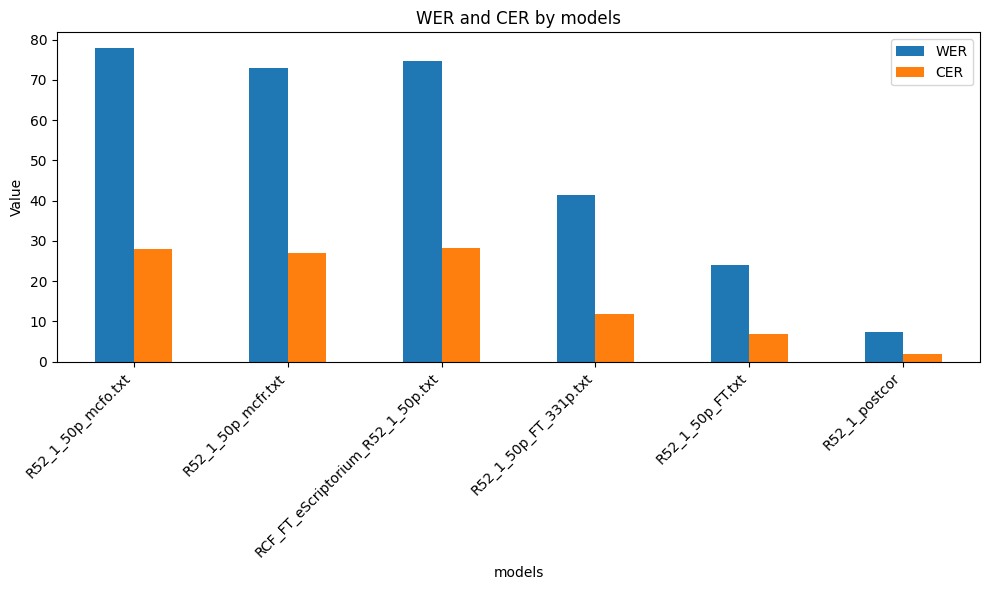

In [6]:
import matplotlib.pyplot as plt


# Se concentrer sur WER et CER
metrics = ["WER", "CER"]

# Plot
df.plot(x="models", y=metrics, kind="bar", figsize=(10,6))
plt.title("WER and CER by models")
plt.ylabel("Value")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Sauvegarder au format PNG
plt.savefig("R52_1_WER_CER_comparison.png", dpi=300)
plt.show()
